# Mini-Project 3 — Lake Victoria Fish Stock & Export Risk Model

**Scenario.** A fish-export cooperative in Jinja wants to know (a) whether its harvesting rate is sustainable and (b) how risky its revenue is. The previous version of this question modelled stock with Fibonacci numbers and flagged risk when revenue variance exceeded 50,000. We replace both with defensible methods.

**Assumptions**
- Time step = 1 week; $r = 0.4$ per week, $K = 10{,}000$ t, $N_0 = 4{,}000$ t, as given. Harvest each week is $h\cdot N(t)$ tonnes.
- Price follows a random walk with weekly changes $\sim \mathcal N(0, 400)$ UGX/kg, starting at 12,000 and clipped to [9,000, 16,000] UGX/kg. The step size of 400 is our assumption (about 3 % a week).
- The **same seeded price path** is used for every harvest scenario (common random numbers), so differences between scenarios come from the harvest policy, not from luck in prices.
- Revenue = harvest (t) × 1,000 kg/t × price (UGX/kg). Costs are ignored (revenue, not profit).

Code: `src/fishstock.py` (classes `FishStock`, `PriceModel`, `RiskAssessor`, `StockTrajectory`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fishstock import FishStock, PriceModel, RiskAssessor, fibonacci, weekly_revenue

SEED = 2026
WEEKS = 52
pd.set_option("display.float_format", "{:,.2f}".format)

## Task 1 — The Fibonacci baseline

In [2]:
fib_stock = fibonacci(15)
print("Fibonacci 'stock':", fib_stock)
print("Growth ratios:", np.round(np.array(fib_stock[1:]) / np.array(fib_stock[:-1]), 3))

Fibonacci 'stock': [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Growth ratios: [1.    2.    1.5   1.667 1.6   1.625 1.615 1.619 1.618 1.618 1.618 1.618
 1.618 1.618]


**Why unbounded Fibonacci growth is biologically unrealistic.** Each term is the sum of the previous two, so the stock grows by about 62 % per step for ever (the ratio tends to 1.618). No real population can do that. Lake Victoria has finite food, oxygen and breeding habitat, so growth must slow as the stock approaches the lake's **carrying capacity**. The sequence also has no deaths, no fishing pressure and no environmental shocks, and it cannot decline. Finally, the numbers do not depend on any measurable biology (growth rate, lake size), so the model cannot be calibrated or tested against catch data.

## Task 2 — `FishStock`: logistic growth with harvesting

In [3]:
base_fish = FishStock(r=0.4, K=10_000, n0=4_000, h=0.10)
print(base_fish)
base_traj = base_fish.simulate(WEEKS)
print(f"Week 0 stock: {base_traj.stock[0]:,.0f} t -> week 1: {base_traj.stock[1]:,.0f} t -> week 52: {base_traj.final_stock:,.1f} t")
print(f"Hand check week 1: 4000 + 0.4*4000*(1 - 4000/10000) - 0.1*4000 = {4000 + 0.4*4000*0.6 - 400:,.0f} t")
print(f"Theory: equilibrium N* = K(1 - h/r) = {base_fish.equilibrium_stock():,.0f} t")

FishStock(r=0.4, K=10,000, n0=4,000, h=0.1)
Week 0 stock: 4,000 t -> week 1: 4,560 t -> week 52: 7,500.0 t
Hand check week 1: 4000 + 0.4*4000*(1 - 4000/10000) - 0.1*4000 = 4,560 t
Theory: equilibrium N* = K(1 - h/r) = 7,500 t


## Task 3 — `PriceModel`: a bounded, seeded random walk

In [4]:
price_model = PriceModel(start=12_000, lower=9_000, upper=16_000, step_sd=400, seed=SEED)
print(price_model)
prices = price_model.simulate(WEEKS)[0]                   # one path, shape (52,)
revenue = weekly_revenue(base_traj.harvest, prices)       # UGX per week
week_df = pd.DataFrame({"stock (t)": base_traj.stock[:-1], "harvest (t)": base_traj.harvest,
                        "price (UGX/kg)": prices, "revenue (UGX bn)": revenue / 1e9},
                       index=pd.Index(range(1, WEEKS + 1), name="Week"))
week_df.iloc[[0, 1, 2, 10, 25, 51]]

PriceModel(start=12,000, bounds=[9,000, 16,000], step_sd=400, seed=2026)


,stock (t),harvest (t),price (UGX/kg),revenue (UGX bn)
Week,,,,
1,"4,000.00",400.00,"12,000.00",4.80
2,"4,560.00",456.00,"11,682.75",5.33
3,"5,096.26",509.63,"11,778.98",6.00
11,"7,271.20",727.12,"11,516.58",8.37
26,"7,498.86",749.89,"11,401.32",8.55
52,"7,500.00",750.00,"16,000.00",12.00


## Task 4 — Revenue statistics, and why a variance threshold of 50,000 is meaningless

In [5]:
assessor = RiskAssessor(low=0.10, high=0.25)
stats_ugx = assessor.describe(revenue)
stats_mugx = assessor.describe(revenue / 1e6)                 # same data in millions of UGX
pd.DataFrame({"revenue in UGX": stats_ugx, "revenue in million UGX": stats_mugx})

,revenue in UGX,revenue in million UGX
mean,"8,862,347,015.85","8,862.35"
median,"8,893,470,327.89","8,893.47"
variance,"1,850,918,709,937,862,144.00","1,850,918.71"
std,"1,360,484,733.45","1,360.48"
cv,0.15,0.15


**Why "variance > 50,000" is meaningless.** Variance is measured in the **square** of the data's units, here UGX². Weekly revenue is in the billions of UGX, so its variance is around $10^{17}$ UGX² and will *always* exceed 50,000, even for an almost perfectly stable business. The table shows the problem directly: the same revenue expressed in *millions* of UGX has a variance $10^{12}$ times smaller, so whether the rule fires depends on the choice of currency unit, not on risk. A threshold also has to scale with the size of the business. The **coefficient of variation** $CV = s/\bar x$ fixes both problems: it has no units, it is identical in both columns, and it measures volatility *relative to typical revenue*.

## Task 5 — `RiskAssessor`: a CV rule, Monte Carlo and 5 % Value-at-Risk

**Rule.** CV < 0.10 → **Low**; 0.10 ≤ CV < 0.25 → **Moderate**; CV ≥ 0.25 → **High**.
*Justification:* with CV = 0.10 a typical week is within about ±10 % of average, which a cooperative can absorb from normal working capital. At CV = 0.25, if revenue is roughly normal, about one week in six falls below 75 % of average ($\bar x - 1s$). That is enough to threaten fixed commitments such as wages, boat loans and cold-chain costs. The cut-offs are policy choices and are parameters of the class, so the cooperative can change them.

In [6]:
print(f"Weekly revenue CV (h = 0.10): {stats_ugx['cv']:.3f} -> risk class: {assessor.classify(stats_ugx['cv'])}")

N_PATHS = 1000
mc_price_model = PriceModel(start=12_000, lower=9_000, upper=16_000, step_sd=400, seed=SEED + 1)
annual = assessor.monte_carlo_annual_revenue(base_traj, mc_price_model, n_paths=N_PATHS)
var = assessor.value_at_risk(annual, level=0.05)
print(f"\nMonte Carlo with {N_PATHS:,} price paths (h = 0.10):")
print(f"  mean annual revenue       : UGX {annual.mean() / 1e9:,.1f} bn")
print(f"  5% quantile of revenue    : UGX {var['quantile'] / 1e9:,.1f} bn")
print(f"  5% VaR (mean - quantile)  : UGX {var['var_vs_mean'] / 1e9:,.1f} bn  ({var['var_vs_mean'] / annual.mean():.1%} of mean)")
print(f"  average revenue in the worst 5% of years: UGX {var['expected_shortfall'] / 1e9:,.1f} bn")

Weekly revenue CV (h = 0.10): 0.154 -> risk class: Moderate

Monte Carlo with 1,000 price paths (h = 0.10):
  mean annual revenue       : UGX 455.1 bn
  5% quantile of revenue    : UGX 375.1 bn
  5% VaR (mean - quantile)  : UGX 80.1 bn  (17.6% of mean)
  average revenue in the worst 5% of years: UGX 366.0 bn


**Interpretation.** In 1 year out of 20, annual revenue is expected to fall at least the VaR amount below its average purely because of price movements, with the same catch. That is the figure the cooperative should hold in reserves or cover with forward contracts.

## Task 6 — Scenario analysis: h = 0.05, 0.10, 0.20, 0.30

In [7]:
H_VALUES = [0.05, 0.10, 0.20, 0.30]
trajectories, annual_by_h, rows = {}, {}, []
for h in H_VALUES:
    fish = FishStock(r=0.4, K=10_000, n0=4_000, h=h)
    traj = fish.simulate(WEEKS)
    rev = weekly_revenue(traj.harvest, prices)                      # same price path for all
    d = assessor.describe(rev)
    ann = assessor.monte_carlo_annual_revenue(traj, mc_price_model, n_paths=N_PATHS)
    trajectories[h], annual_by_h[h] = traj, ann
    rows.append({
        "h": h,
        "final stock (t)": traj.final_stock,
        "equilibrium N* (t)": fish.equilibrium_stock(),
        "week-52 catch (t/wk)": traj.harvest[-1],
        "sustainable yield hN* (t/wk)": fish.sustainable_yield(),
        "MSY rK/4 (t/wk)": fish.msy,
        "total revenue (UGX bn)": rev.sum() / 1e9,
        "weekly CV": d["cv"],
        "risk class": assessor.classify(d["cv"]),
        "5% VaR (UGX bn)": assessor.value_at_risk(ann)["var_vs_mean"] / 1e9,
        "vs MSY": "at MSY" if np.isclose(h, fish.h_msy) else ("below MSY rate" if h < fish.h_msy else "OVERFISHING"),
    })
scenario_df = pd.DataFrame(rows).set_index("h")
scenario_df

,final stock (t),equilibrium N* (t),week-52 catch (t/wk),sustainable yield hN* (t/wk),MSY rK/4 (t/wk),total revenue (UGX bn),weekly CV,risk class,5% VaR (UGX bn),vs MSY
h,,,,,,,,,,
0.05,"8,750.00","8,750.00",437.50,437.50,"1,000.00",267.89,0.17,Moderate,46.72,below MSY rate
0.10,"7,500.00","7,500.00",750.00,750.00,"1,000.00",460.84,0.15,Moderate,80.05,below MSY rate
0.20,"4,999.99","5,000.00","1,000.00","1,000.00","1,000.00",626.79,0.11,Moderate,107.24,at MSY
0.30,"2,503.72","2,500.00",751.24,750.00,"1,000.00",520.54,0.12,Moderate,84.30,OVERFISHING


**Comparison with MSY.** Theory says the sustainable catch at rate $h$ is $hK(1 - h/r)$, which peaks at $h = r/2 = 0.20$ with **MSY = rK/4 = 1,000 t/week**, when the stock is held at $K/2 = 5{,}000$ t. The simulation agrees: after 52 weeks each stock has settled at $N^*$, and the weekly catch equals the theoretical yield (437.5, 750, 1,000, 750 t).

- **h = 0.05 and 0.10** are sustainable but **under-harvest**: the stock stays large, but the catch is 44 % and 75 % of MSY.
- **h = 0.20** achieves MSY and the highest total revenue.
- **h = 0.30** is **overfishing**. The first weeks are lucrative because a large stock is being mined, but the stock is driven down to 2,500 t and the long-run catch falls back to 750 t/week, the *same* as h = 0.10 with a third of the fish left in the lake. It earns less than h = 0.20 while carrying much more ecological risk.

The **risk class is "Moderate" for every h**. This is an important result: CV measures *price* volatility relative to revenue, and changing $h$ scales revenue up or down without changing its relative volatility. **CV-based risk cannot detect biological risk**, so the sustainability check against MSY must be reported alongside it, as in the last column.

## Task 7 — Charts

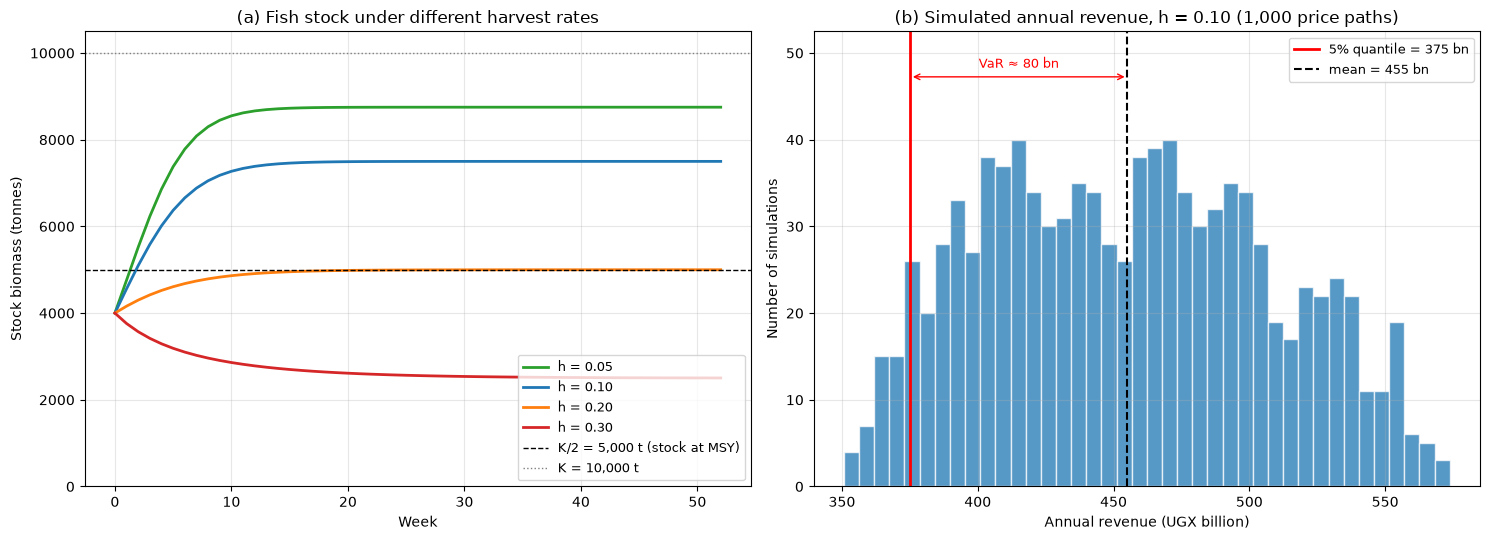

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
colours = {0.05: "tab:green", 0.10: "tab:blue", 0.20: "tab:orange", 0.30: "tab:red"}
for h, traj in trajectories.items():
    ax.plot(range(WEEKS + 1), traj.stock, color=colours[h], lw=2, label=f"h = {h:.2f}")
ax.axhline(5_000, color="black", ls="--", lw=1, label="K/2 = 5,000 t (stock at MSY)")
ax.axhline(10_000, color="grey", ls=":", lw=1, label="K = 10,000 t")
ax.set(title="(a) Fish stock under different harvest rates", xlabel="Week", ylabel="Stock biomass (tonnes)", ylim=(0, 10_500))
ax.legend(loc="lower right", fontsize=9); ax.grid(alpha=0.3)

ax = axes[1]
ann_bn = annual / 1e9
ax.hist(ann_bn, bins=40, color="tab:blue", alpha=0.75, edgecolor="white")
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)   # headroom for the VaR annotation
ax.axvline(var["quantile"] / 1e9, color="red", lw=2, label=f"5% quantile = {var['quantile']/1e9:,.0f} bn")
ax.axvline(ann_bn.mean(), color="black", ls="--", lw=1.5, label=f"mean = {ann_bn.mean():,.0f} bn")
ax.annotate("", xy=(var["quantile"] / 1e9, ax.get_ylim()[1] * 0.9), xytext=(ann_bn.mean(), ax.get_ylim()[1] * 0.9),
            arrowprops=dict(arrowstyle="<->", color="red"))
ax.text((var["quantile"] / 1e9 + ann_bn.mean()) / 2, ax.get_ylim()[1] * 0.92, f"VaR ≈ {var['var_vs_mean']/1e9:,.0f} bn",
        ha="center", color="red", fontsize=9)
ax.set(title=f"(b) Simulated annual revenue, h = 0.10 ({N_PATHS:,} price paths)",
       xlabel="Annual revenue (UGX billion)", ylabel="Number of simulations")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/p3_stock_and_var.png", dpi=150); plt.show()

## Extension — An 8-week closed season, evaluated over 5 years

In [9]:
YEARS5 = 5
W5 = WEEKS * YEARS5
closed = np.zeros(W5, dtype=bool)
for y in range(YEARS5):
    closed[y * WEEKS + 12 : y * WEEKS + 20] = True          # weeks 13-20 each year (~April-May, illustrative breeding season)
prices5 = PriceModel(seed=SEED).simulate(W5)[0]

ext_rows, ext_traj = [], {}
for h in H_VALUES:
    fish = FishStock(h=h)
    open_all = fish.simulate(W5)
    with_closure = fish.simulate(W5, closed_weeks=closed)
    ext_traj[h] = (open_all, with_closure)
    r_open = weekly_revenue(open_all.harvest, prices5).sum()
    r_closed = weekly_revenue(with_closure.harvest, prices5).sum()
    ext_rows.append({"h": h, "5-yr revenue, no closure (UGX bn)": r_open / 1e9,
                     "5-yr revenue, closed season (UGX bn)": r_closed / 1e9,
                     "change (%)": (r_closed / r_open - 1) * 100,
                     "min stock, no closure (t)": open_all.stock.min(),
                     "min stock, closed season (t)": with_closure.stock.min()})
pd.DataFrame(ext_rows).set_index("h")

,"5-yr revenue, no closure (UGX bn)","5-yr revenue, closed season (UGX bn)",change (%),"min stock, no closure (t)","min stock, closed season (t)"
h,,,,,
0.05,"1,538.78","1,317.83",-14.36,"4,000.00","4,000.00"
0.10,"2,639.51","2,287.44",-13.34,"4,000.00","4,000.00"
0.20,"3,531.68","3,211.27",-9.07,"4,000.00","4,000.00"
0.30,"2,699.38","2,890.97",7.10,"2,500.00","2,515.13"


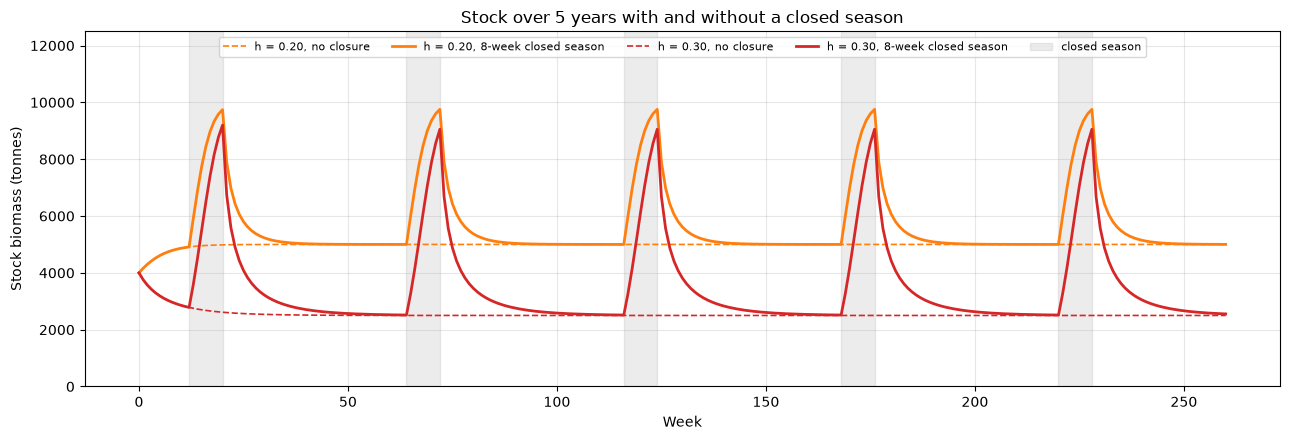

In [10]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for h, ls in [(0.20, "-"), (0.30, "-")]:
    o, c = ext_traj[h]
    ax.plot(o.stock, color=colours[h], lw=1.2, ls="--", label=f"h = {h:.2f}, no closure")
    ax.plot(c.stock, color=colours[h], lw=2, label=f"h = {h:.2f}, 8-week closed season")
for y in range(YEARS5):
    ax.axvspan(y * WEEKS + 12, y * WEEKS + 20, color="grey", alpha=0.15, label="closed season" if y == 0 else None)
ax.set(title="Stock over 5 years with and without a closed season", xlabel="Week", ylabel="Stock biomass (tonnes)", ylim=(0, 12_500))
ax.legend(ncol=5, fontsize=8, loc="upper center"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/p3_closed_season.png", dpi=150); plt.show()

**Effect of the closed season.** It depends on whether the fishery is being over-harvested:
- At **h = 0.30 (overfishing)** the closed season *raises* 5-year revenue. The eight weeks of rest let the stock rebuild towards the productive $K/2$ level, and the extra catch afterwards more than repays the weeks lost.
- At **h ≤ 0.20** it *reduces* revenue. The stock is already at or above its most productive level, so a closure only gives up catch that growth would have replaced.

A closed season is therefore a useful safeguard when the harvest rate is too high or uncertain, but at a well-set harvest rate it costs money. In this model, setting $h$ close to 0.20 achieves more than a closure does. (Real closed seasons also protect *spawning* fish and juveniles, which a single-biomass model cannot represent; see Limitations.)

## Findings & Limitations

**Findings.** (a) *Sustainability.* The cooperative's harvest rate should be set against the MSY benchmark. With $r = 0.4$ and $K = 10{,}000$ t, the best sustainable policy is $h = 0.20$: it holds the stock at 5,000 t and lands the maximum 1,000 t/week, earning the highest revenue. Rates of 0.05–0.10 are safe but leave 25–56 % of the potential catch in the water. At $h = 0.30$ the stock is overfished and settles at the *same* 750 t/week as $h = 0.10$ with only a third of the biomass left. (b) *Revenue risk.* The old variance-over-50,000 rule is unit-dependent and would flag every scenario. Using CV, all scenarios are **Moderate** risk (CV 0.11–0.17), and the 5 % VaR at $h = 0.10$ is about UGX 80 bn (≈18 % of expected annual revenue). CV cannot distinguish $h = 0.20$ from the overfished $h = 0.30$, so a financial risk metric must be paired with a biological one. The closed-season extension supports this: closures raise long-run revenue only when fishing is too intense (+7 % at $h = 0.30$) and cost 9–14 % otherwise.

**Limitations.** (1) The parameters are illustrative. A weekly $r = 0.4$ makes recovery implausibly fast, and the implied catches exceed a single cooperative's scale. (2) The logistic model treats the stock as one biomass with no age structure, spawning or environmental variability, so it cannot capture recruitment failure or the reason real closed seasons exist (protecting breeders). (3) The price walk is independent of catch, but in reality large landings can depress prices. (4) The ±400 UGX step and the price bounds drive the VaR directly, and they are assumptions.